# Jev battery versions v0, v1 and v2: results, findings and decisions

**Study:** Implication-Weighted Data Selection for Financial QA — Protocol v1 (training-free).

This notebook documents how the Jev question battery developed between 24 and 25 October 2026. It covers:

- the three wordings;
- every result obtained with each;
- the criteria fixed before each test, and the outcomes;
- the decisions taken, and why;
- what all of this means for the paper's thesis, hypotheses and gates.

**Purely descriptive.** The notebook reads only frozen snapshots in `code/runs/` (each with a `SHA256SUMS` file, verified below) and the three battery files in `code/prompts/`. It imports nothing from the pipeline, calls no API, and changes no code, configuration or experiment output. Its only outputs are this notebook and `notebooks/figures/battery_*.pdf`.

| Run | Battery | Sample | Snapshot |
|---|---|---|---|
| Pilot v0 | v0 | 200 originals + 99 negatives | `code/runs/pilot_2026-10-24/` |
| Pilot v1 | v1 | same items | `code/runs/pilot_v1_2026-10-24/` |
| Pilot v2 | v2 | same items | `code/runs/pilot_v2_2026-10-25/` |
| Full v0 | v0 | 19,258 originals + 997 negatives | `code/runs/full_v0_2026-10-24/` |
| Full v2 | v2 | same items | `code/runs/full_v2_2026-10-25/` |

## 0. Why the battery matters for the thesis

The thesis decomposes an example's value into:

- **reliability R** = P(datum is true);
- **implication strength I** = P(task-relevant consequence | datum is true);
- **surprisal S**.

The central claim (H4) is that **I moderates whether surprising data is useful**. A result that reduces to "clean labels help" is a null result.

The decomposition works only if Jev's I measures something other than R. In the protocol:

- **R** = P(yes) on Q1 (support).
- **I** = the mean of P(yes) on **Q2 (determinacy)** and **Q3 (consequence)**.

Two parts of the protocol depend on that separation:

- **Gate D3** stops the study before E1 if |ρ(R, I)| ≥ 0.8. Its remedy is to "revise Q2 and Q3".
- **Spec 1** expects that "only Q1 should separate negatives from originals". A wrong answer should lower R, but not I, since I is defined as conditional on the datum being true.

This notebook is about that requirement. Under the original wording, Q2 behaved like a second correctness question.

## 1. Setup and integrity of the snapshots

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy import stats
from sklearn.metrics import roc_auc_score

CODE = Path.cwd().parent / "code"
RUNS = {"pilot v0": "pilot_2026-10-24", "pilot v1": "pilot_v1_2026-10-24", "pilot v2": "pilot_v2_2026-10-25",
        "full v0": "full_v0_2026-10-24", "full v2": "full_v2_2026-10-25"}
FIG_DIR = Path.cwd() / "figures"
FIG_DIR.mkdir(exist_ok=True)
N_BOOT = 2000
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"v0": "#9a9a9a", "v1": "#d1603d", "v2": "#3b6ea5"}


def verify(folder: Path) -> bool:
    for line in (folder / "SHA256SUMS").read_text().splitlines():
        digest, rel = line.split(maxsplit=1)
        if hashlib.sha256((folder / rel).read_bytes()).hexdigest() != digest:
            return False
    return True

for name, d in RUNS.items():
    print(f"{name:9s} {d:22s} checksums verified: {verify(CODE / 'runs' / d)}")

pilot v0  pilot_2026-10-24       checksums verified: True
pilot v1  pilot_v1_2026-10-24    checksums verified: True
pilot v2  pilot_v2_2026-10-25    checksums verified: True
full v0   full_v0_2026-10-24     checksums verified: True
full v2   full_v2_2026-10-25     checksums verified: True


In [2]:
QMAP = {("orig", "q1"): "q1", ("orig", "q2"): "q2", ("orig", "q3"): "q3",
        ("para", "q1"): "q1p", ("para", "q2"): "q2p", ("para", "q3"): "q3p"}


def load_run(name):
    root = CODE / "runs" / RUNS[name]
    long = pd.read_parquet(root / "scores" / "jev_scores_long.parquet")
    scores = pd.read_parquet(root / "scores" / "jev_scores.parquet")
    pool = pd.read_parquet(root / "data" / "pool.parquet")[["item_id", "dataset", "answer_type", "base_item_id"]]
    q = long.assign(qid=[QMAP[(b, x)] for b, x in zip(long["battery"], long["question"])]) \
            .pivot(index="item_id", columns="qid", values="p_yes")
    df = scores.merge(pool, on="item_id").set_index("item_id").join(q)
    orig = df[~df["is_negative"]]
    neg = df[df["is_negative"]]
    pairs = neg[neg["base_item_id"].isin(orig.index)]
    manifest = json.loads((root / "results" / "jev_manifest.json").read_text())
    reqs = pd.read_parquet(root / "scores" / "jev_requests.parquet")
    return {"df": df, "orig": orig, "neg": neg, "pairs": pairs, "manifest": manifest, "reqs": reqs}

R = {name: load_run(name) for name in RUNS}
for name, r in R.items():
    print(f"{name:9s} battery {r['manifest'].get('battery_version', 'v0'):3s} originals {len(r['orig']):6,d} "
          f"negatives {len(r['neg']):5,d} pairs {len(r['pairs']):5,d}  jev {r['manifest']['jev_model_version']}")

pilot v0  battery v0  originals    200 negatives    99 pairs    99  jev jev-1.14.0
pilot v1  battery v1  originals    200 negatives    99 pairs    99  jev jev-1.14.0
pilot v2  battery v2  originals    200 negatives    99 pairs    99  jev jev-1.14.0
full v0   battery v0  originals 19,258 negatives   997 pairs   995  jev jev-1.14.0
full v2   battery v2  originals 19,258 negatives   997 pairs   995  jev jev-1.14.0


The pilot v0 manifest predates the `battery_version` field, which was added when the battery files were versioned. It was scored with the v0 file, as was the full v0 run.

## 2. The three wordings

Q1, Q3, Q1′ and Q3′ are identical in all versions. Only the determinacy questions Q2 and Q2′ change, together with, in v2, the state they are asked against.

In [3]:
bat = {v: yaml.safe_load((CODE / "prompts" / f"jev_battery_{v}.yaml").read_text()) for v in ("v0", "v1", "v2")}
for b in ("orig", "para"):
    for q in ("q1", "q3"):
        assert bat["v0"][b][q] == bat["v1"][b][q] == bat["v2"][b][q]
rows = []
for v in ("v0", "v1", "v2"):
    state = "context + question (no stated answer)" if "q2" in bat[v].get("answer_free", []) else "context + question + stated answer"
    rows.append({"battery": v, "Q2": bat[v]["orig"]["q2"], "Q2′ (paraphrase)": bat[v]["para"]["q2"], "Q2 state": state})
wording = pd.DataFrame(rows).set_index("battery")
with pd.option_context("display.max_colwidth", None):
    display(wording)
print("Unchanged in all versions:")
for b in ("orig", "para"):
    for q in ("q1", "q3"):
        print(f"  {QMAP[(b, q)]}: {bat['v0'][b][q]}")

,Q2,Q2′ (paraphrase),Q2 state
battery,,,
v0,"Do the context and question determine this answer uniquely, such that no materially different answer would also be defensible?","Is this the only reasonable answer to the question given the information, rather than one of several defensible answers?",context + question + stated answer
v1,"Assume the stated answer is correct. Is the question, read against the context, specific enough that no materially different answer could also be correct?","Suppose the answer given is right. Does the information pin the question down so that only one answer, and no materially different one, could be right?",context + question + stated answer
v2,"Do the context and question determine a single answer uniquely, such that no materially different answer would also be defensible?","Is there only one reasonable answer to this question given the information, rather than several defensible answers?",context + question (no stated answer)


Unchanged in all versions:
  q1: Given the context and question, is the stated answer supported by the context?
  q3: Assume the stated answer is true. Does it entail the following check? Check: {check_text}
  q1p: Does the information provided back up the answer given to this question?
  q3p: If the answer given is correct, must the following statement also be correct? Statement: {check_text}


| Version | Idea | Design consequence |
|---|---|---|
| **v0** (pre-registered) | Determinacy: does the context determine *this answer* uniquely? | Q2 sees the stated answer, so a wrong answer looks "not determined" |
| **v1** | Condition on truth, as Q3 does: *assume the stated answer is correct* | Still sees the answer; the assumption contradicts the context when the answer is wrong |
| **v2** | Determinacy as a property of the question: does the context pin down *a single answer*? | Asked on a state **without** the stated answer, so an original and its negative get the same Q2 by construction. Costs one extra request per distinct question |

## 3. Timeline and decisions

The battery's history, reconstructed from the implementation plan's decisions log and verification log. Times are UTC.

| When | Step | Evidence | Decision |
|---|---|---|---|
| 24 Oct | Pilot v0 Jev run and analysis | ρ(Q1, Q2) = 0.87; Q2 separates wrong answers (AUROC 0.90) almost as well as Q1; ρ(R, I) = 0.73 [0.65, 0.79] | Q2 coupling raised as an open owner question (blocking question 4); full run proceeds with v0 meanwhile |
| 24 Oct | Full v0 run (19,258 originals) | ρ(R, I) = 0.67 overall but **0.80 on FinQA**; ρ(Q1, Q2) = 0.82 | Owner asks for a revised Q2 |
| 25 Oct 00:11 | **v1 criteria recorded before scoring**: C1 Q2 AUROC on negatives ≤ 0.75; C2 ρ(Q1, Q2) ≤ 0.50; C3 Q2 spread; C4 ρ(Q2, Q2′) ≥ 0.70. Rule: if any fails, do not re-score or tune; the owner decides | — | — |
| 25 Oct | Pilot v1 | C1 0.85 ✗, C2 0.75 ✗, C3 ✓, C4 ✓ | **v1 rejected**; owner chooses the fallback (Q2 without the stated answer) |
| 25 Oct 00:26 | **v2 criteria recorded before scoring**: C1 replaced by C1′ (Q2 identical across each original/negative pair, a construction check), because C1 equals 0.5 by construction under v2; C2–C4 unchanged | — | — |
| 25 Oct | Pilot v2 | C1′ ✓, **C2 0.58 ✗**, C3 ✓, C4 ✓ | Owner chooses option 3: **v2 primary despite C2, as a disclosed exception; v0 as the pre-registered sensitivity analysis** |
| 25 Oct | Full v2 run (19,258 originals) | ρ(R, I) = 0.46 (FinQA 0.52); ρ(Q1, Q2) = 0.48; AUROC of R unchanged (0.94); I's AUROC on negatives 0.71 (v0 0.93) | v2 scores become the primary Jev scores; v0 full run kept as the sensitivity analysis |

The reference values in the v1 criteria table were first written partly from memory. They were corrected from the data before any v1 score existed, and the thresholds did not change. The plan records this.

Two unrelated decisions from the same period affect all versions equally:
- **Determinism tolerance:** raised from 0.01 to 0.017 after the pilot (owner decision, pilot-informed). Every run in this notebook used single scoring under it, except the first pilot v0 run, whose scores were then rebuilt from cache under 0.017.
- **Jev version:** every run used `jev-1.14.0`.

## 4. Measurement cost and stability by run

The determinism and batching checks were repeated in every run, on that run's own 200-item sample. v2 sends two requests per item; the answer-free one is shared by an original and its negative.

In [4]:
mrows = []
for name, r in R.items():
    m = r["manifest"]
    mrows.append({"run": name, "battery": m.get("battery_version", "v0"),
                  "repeat |ΔP|": m["determinism"]["mean_abs_diff"], "tolerance": m["determinism"]["tolerance"],
                  "triplicate": m["determinism"]["triplicate"],
                  "batched − single": m["batching"]["mean_abs_diff_batched_vs_single"],
                  "allowed": m["batching"]["allowed"], "mode": m["batching"]["mode"],
                  "scoring requests": m["full_run"]["requests"], "scoring input tokens (M)": m["full_run"]["input_tokens"] / 1e6})
display(pd.DataFrame(mrows).set_index("run"))

,battery,repeat |ΔP|,tolerance,triplicate,batched − single,allowed,mode,scoring requests,scoring input tokens (M)
run,,,,,,,,,
pilot v0,v0,0.016,0.017,False,0.015,0.026,batched,299,0.383
pilot v1,v1,0.016,0.017,False,0.017,0.026,batched,299,0.387
pilot v2,v2,0.015,0.017,False,0.016,0.025,batched,499,0.598
full v0,v0,0.012,0.017,False,0.012,0.022,batched,20255,23.593
full v2,v2,0.012,0.017,False,0.012,0.022,batched,39515,42.144


## 5. Pilot comparison: the pre-recorded criteria

The same 200 originals and 99 original/negative pairs were scored with each battery.

- **Spearman correlations:** reported with Fisher-z 95% intervals.
- **AUROCs:** use a cluster bootstrap over pairs (2,000 resamples), as in Spec 3.

In [5]:
def rho_ci(x, y):
    r = stats.spearmanr(x, y)[0]
    z, se = np.arctanh(r), 1 / np.sqrt(len(x) - 3)
    return r, np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se)


def auc_ci(r, col, n=N_BOOT, seed=0):
    df, pairs = r["df"], r["pairs"]
    pos = df.loc[pairs["base_item_id"], col].to_numpy()
    neg = pairs[col].to_numpy()
    def auc(idx):
        return roc_auc_score(np.r_[np.ones(len(idx)), np.zeros(len(idx))], np.r_[pos[idx], neg[idx]])
    g = np.random.default_rng(seed)
    reps = [auc(g.integers(0, len(pos), len(pos))) for _ in range(n)]
    return auc(np.arange(len(pos))), *np.percentile(reps, [2.5, 97.5])


def fmt(t):
    return f"{t[0]:.3f} [{t[1]:.3f}, {t[2]:.3f}]"


def metrics(r, boot=True):
    o, df, pairs = r["orig"], r["df"], r["pairs"]
    same = bool(np.array_equal(df.loc[pairs["base_item_id"], ["q2", "q2p"]].to_numpy(), pairs[["q2", "q2p"]].to_numpy()))
    out = {
        "C1 / C1′: Q2 identical in every pair": same,
        "C1: AUROC of Q2 on negatives": fmt(auc_ci(r, "q2")) if boot else None,
        "C2: ρ(Q1, Q2)": fmt(rho_ci(o["q1"], o["q2"])),
        "C3: SD of Q2": f"{o['q2'].std(ddof=1):.3f}",
        "C3: share Q2 ≥ 0.99": f"{(o['q2'] >= 0.99).mean():.3f}",
        "C4: ρ(Q2, Q2′)": fmt(rho_ci(o["q2"], o["q2p"])),
        "ρ(R, I)": fmt(rho_ci(o["R"], o["I"])),
        "ρ(R, I) FinQA": fmt(rho_ci(o.loc[o["dataset"] == "finqa", "R"], o.loc[o["dataset"] == "finqa", "I"])),
        "ρ(R, I) TAT-QA": fmt(rho_ci(o.loc[o["dataset"] == "tatqa", "R"], o.loc[o["dataset"] == "tatqa", "I"])),
        "ρ(Q2, Q3)": fmt(rho_ci(o["q2"], o["q3"])),
        "AUROC of R on negatives": fmt(auc_ci(r, "R")) if boot else None,
        "AUROC of I on negatives": fmt(auc_ci(r, "I")) if boot else None,
        "AUROC of Q3 on negatives": fmt(auc_ci(r, "q3")) if boot else None,
        "median Q2 (originals)": f"{o['q2'].median():.3f}",
        "ρ(R, R′)": fmt(rho_ci(o["R"], o["R_para"])),
        "ρ(I, I′)": fmt(rho_ci(o["I"], o["I_para"])),
    }
    return pd.Series(out)

pilot = pd.DataFrame({v: metrics(R[f"pilot {v}"]) for v in ("v0", "v1", "v2")})
with pd.option_context("display.max_colwidth", None):
    display(pilot)

,v0,v1,v2
C1 / C1′: Q2 identical in every pair,False,False,True
C1: AUROC of Q2 on negatives,"0.901 [0.860, 0.941]","0.849 [0.799, 0.897]","0.500 [0.500, 0.500]"
"C2: ρ(Q1, Q2)","0.874 [0.836, 0.903]","0.748 [0.680, 0.803]","0.582 [0.482, 0.667]"
C3: SD of Q2,0.222,0.203,0.202
C3: share Q2 ≥ 0.99,0.000,0.000,0.000
"C4: ρ(Q2, Q2′)","0.954 [0.940, 0.965]","0.951 [0.936, 0.963]","0.965 [0.954, 0.974]"
"ρ(R, I)","0.726 [0.653, 0.785]","0.655 [0.568, 0.727]","0.530 [0.422, 0.623]"
"ρ(R, I) FinQA","0.762 [0.665, 0.833]","0.712 [0.600, 0.797]","0.460 [0.289, 0.602]"
"ρ(R, I) TAT-QA","0.598 [0.454, 0.711]","0.469 [0.300, 0.609]","0.448 [0.276, 0.592]"
"ρ(Q2, Q3)","0.179 [0.041, 0.310]","0.133 [-0.006, 0.266]","0.086 [-0.053, 0.222]"


In [6]:
crit = pd.DataFrame([
    ["C1", "AUROC of Q2 on negatives ≤ 0.75", "✗ 0.90", "✗ 0.85", "n/a (0.5 by construction)"],
    ["C1′", "Q2 identical for every original/negative pair (v2 only)", "—", "—", "✓"],
    ["C2", "ρ(Q1, Q2) ≤ 0.50", "✗ 0.87", "✗ 0.75", "✗ 0.58"],
    ["C3", "SD(Q2) ≥ 0.10 and ≤ 20% at ≥ 0.99", "✓", "✓", "✓"],
    ["C4", "ρ(Q2, Q2′) ≥ 0.70", "✓ 0.95", "✓ 0.95", "✓ 0.97"],
    ["Outcome", "", "pre-registered", "rejected", "kept as primary (disclosed exception on C2)"],
], columns=["criterion", "rule", "v0", "v1", "v2"]).set_index("criterion")
display(crit)

,rule,v0,v1,v2
criterion,,,,
C1,AUROC of Q2 on negatives ≤ 0.75,✗ 0.90,✗ 0.85,n/a (0.5 by construction)
C1′,Q2 identical for every original/negative pair ...,—,—,✓
C2,"ρ(Q1, Q2) ≤ 0.50",✗ 0.87,✗ 0.75,✗ 0.58
C3,SD(Q2) ≥ 0.10 and ≤ 20% at ≥ 0.99,✓,✓,✓
C4,"ρ(Q2, Q2′) ≥ 0.70",✓ 0.95,✓ 0.95,✓ 0.97
Outcome,,pre-registered,rejected,kept as primary (disclosed exception on C2)


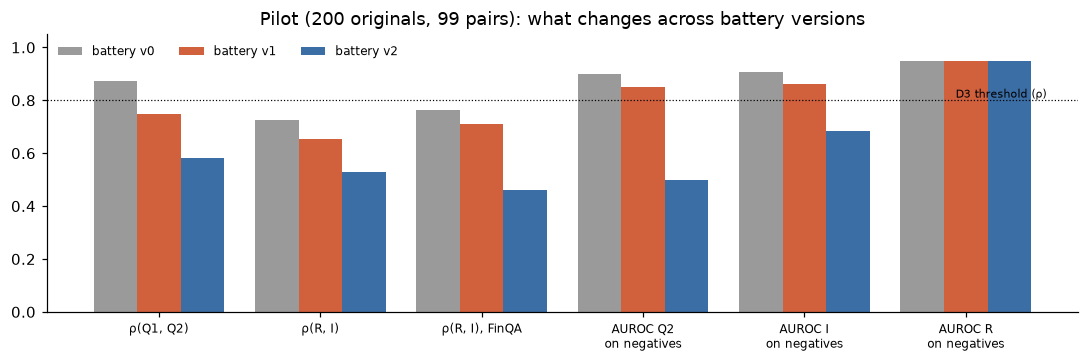

In [7]:
def num(s):
    return float(str(s).split()[0])

keys = ["C2: ρ(Q1, Q2)", "ρ(R, I)", "ρ(R, I) FinQA", "C1: AUROC of Q2 on negatives", "AUROC of I on negatives", "AUROC of R on negatives"]
labels = ["ρ(Q1, Q2)", "ρ(R, I)", "ρ(R, I), FinQA", "AUROC Q2\non negatives", "AUROC I\non negatives", "AUROC R\non negatives"]
fig, ax = plt.subplots(figsize=(10, 3.4))
x = np.arange(len(keys))
for k, v in enumerate(("v0", "v1", "v2")):
    ax.bar(x + (k - 1) * 0.27, [num(pilot.loc[key, v]) for key in keys], 0.27, color=COLORS[v], label=f"battery {v}")
ax.axhline(0.8, ls=":", color="black", lw=0.8)
ax.text(len(keys) - 0.5, 0.81, "D3 threshold (ρ)", fontsize=7, ha="right")
ax.set_xticks(x, labels, fontsize=8)
ax.set_ylim(0, 1.05)
ax.set_title("Pilot (200 originals, 99 pairs): what changes across battery versions")
ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "battery_pilot_comparison.pdf", bbox_inches="tight")
plt.show()

**Findings from the pilots.**

- **Rewording alone was not enough.** v1's "assume the stated answer is correct" lowered the coupling (ρ(Q1, Q2) 0.87 → 0.75), but Q2 still separated wrong answers (AUROC 0.85). When the answer is wrong, the assumption contradicts the context, and Jev reports the question as less determinate. The reworded paraphrase Q2′ did not change behaviour at all.
- **Removing the answer from the state removed the leakage by construction.** Under v2, Q2's AUROC on negatives is exactly 0.5, so it no longer carries correctness information. ρ(R, I) fell from 0.73 to 0.53, and from 0.76 to 0.46 on FinQA.
- **A residual coupling remained**, and it cannot be leakage: ρ(Q1, Q2) = 0.58 even though Q2 cannot see the answer. It is item-level covariance: questions the context leaves less determinate also tend to have gold answers that look less supported.
- **Unaffected throughout:** R, paraphrase agreement and the spread of Q2. R's AUROC stayed at 0.95 in every version.

## 6. Full-pool comparison: v0 (sensitivity) versus v2 (primary)

The same 19,258 originals and 997 negatives, scored with both batteries. Q1 and Q3 have the same wording in both, but under v2 they share a request with three other questions instead of five, so small differences in R are expected. Their size shows how much batching composition matters.

In [8]:
full = pd.DataFrame({v: metrics(R[f"full {v}"]) for v in ("v0", "v2")})
with pd.option_context("display.max_colwidth", None):
    display(full)

,v0,v2
C1 / C1′: Q2 identical in every pair,False,True
C1: AUROC of Q2 on negatives,"0.922 [0.910, 0.934]","0.500 [0.500, 0.500]"
"C2: ρ(Q1, Q2)","0.823 [0.818, 0.827]","0.484 [0.473, 0.495]"
C3: SD of Q2,0.214,0.184
C3: share Q2 ≥ 0.99,0.014,0.000
"C4: ρ(Q2, Q2′)","0.940 [0.939, 0.942]","0.954 [0.952, 0.955]"
"ρ(R, I)","0.674 [0.666, 0.681]","0.458 [0.446, 0.469]"
"ρ(R, I) FinQA","0.804 [0.795, 0.812]","0.516 [0.498, 0.534]"
"ρ(R, I) TAT-QA","0.560 [0.548, 0.572]","0.356 [0.341, 0.371]"
"ρ(Q2, Q3)","0.207 [0.193, 0.220]","0.157 [0.144, 0.171]"


**Findings on the full pool.** Every pilot finding holds, with tighter intervals:

- **Leakage gone:** under v2, Q2's AUROC on wrong answers falls from 0.92 to 0.50, and I's from 0.93 to 0.71. What remains in I comes from Q3, whose check is regenerated from the wrong answer.
- **Weaker coupling:** ρ(R, I) falls from 0.67 to 0.46, and on FinQA from 0.80 to 0.52.
- **R, paraphrase agreement and spread unchanged:** R's AUROC is 0.94 under both versions.
- **C2 on the full pool:** ρ(Q1, Q2) under v2 is **0.48 [0.47, 0.50]**, *below* the 0.50 threshold that v2 missed on the pilot (0.58 [0.48, 0.67]). The pilot's interval reached down to the full-pool value, and the pilot's 50/50 dataset balance weights FinQA, where the coupling is stronger, more heavily. This does not retroactively satisfy the criterion. The decision was taken on the pilot and stays a disclosed exception. But the paper should report that the full-pool value falls within the pre-set bound.

In [9]:
f0, f2 = R["full v0"]["orig"], R["full v2"]["orig"].reindex(R["full v0"]["orig"].index)
cmp = pd.DataFrame({
    "ρ(v0, v2)": {c: stats.spearmanr(f0[c], f2[c])[0] for c in ("R", "q1", "q2", "q3", "I", "V")},
    "mean |v2 − v0|": {c: (f2[c] - f0[c]).abs().mean() for c in ("R", "q1", "q2", "q3", "I", "V")},
    "mean v0": {c: f0[c].mean() for c in ("R", "q1", "q2", "q3", "I", "V")},
    "mean v2": {c: f2[c].mean() for c in ("R", "q1", "q2", "q3", "I", "V")},
})
display(cmp)

,"ρ(v0, v2)",mean |v2 − v0|,mean v0,mean v2
R,0.967,0.011,0.879,0.879
q1,0.967,0.011,0.879,0.879
q2,0.741,0.101,0.819,0.801
q3,0.981,0.011,0.884,0.884
I,0.859,0.052,0.852,0.843
V,0.937,0.040,0.774,0.754


**What changed between v0 and v2 item by item.**

- **R is effectively unchanged.** ρ(R v0, R v2) = 0.97, the means are identical, and the typical difference is 0.01, about the size of call-to-call noise. Moving Q1 from a six-question to a four-question request does not change it measurably. So the R ≥ 0.9 reliability filter selects the same items under both batteries.
- **Q3 is likewise unchanged** (ρ 0.98).
- **Q2 changes the most** (ρ 0.74, mean difference 0.10), and I with it (ρ 0.86).

### 6.1 Gate D3 and the R–I decomposition

D3 fires if |ρ(R, I)| ≥ 0.8 on pool originals (Spec 3, A2). Spec 3 reports the correlation overall and within each dataset.

In [10]:
d3 = []
for v in ("v0", "v2"):
    o = R[f"full {v}"]["orig"]
    for label, g in (("all", o), ("FinQA", o[o["dataset"] == "finqa"]), ("TAT-QA", o[o["dataset"] == "tatqa"])):
        r_, lo, hi = rho_ci(g["R"], g["I"])
        d3.append({"battery": v, "subset": label, "n": len(g), "ρ(R, I)": r_, "CI low": lo, "CI high": hi,
                   "≥ 0.8?": hi >= 0.8 if label != "all" else r_ >= 0.8})
display(pd.DataFrame(d3).set_index(["battery", "subset"]))

n  ρ(R, I)  CI low  CI high  ≥ 0.8?
battery subset                                         
v0      all     19258    0.674   0.666    0.681   False
        FinQA    6143    0.804   0.795    0.812    True
        TAT-QA  13115    0.560   0.548    0.572   False
v2      all     19258    0.458   0.446    0.469   False
        FinQA    6143    0.516   0.498    0.534   False
        TAT-QA  13115    0.356   0.341    0.371   False

**D3.** Under v0 the gate passes overall (0.67) but FinQA alone crosses 0.8 (0.80 [0.795, 0.812]). Under v2 every subset is far below 0.8: overall 0.46, FinQA 0.52, TAT-QA 0.36. With the primary battery, D3 would not fire, and it would not be borderline.

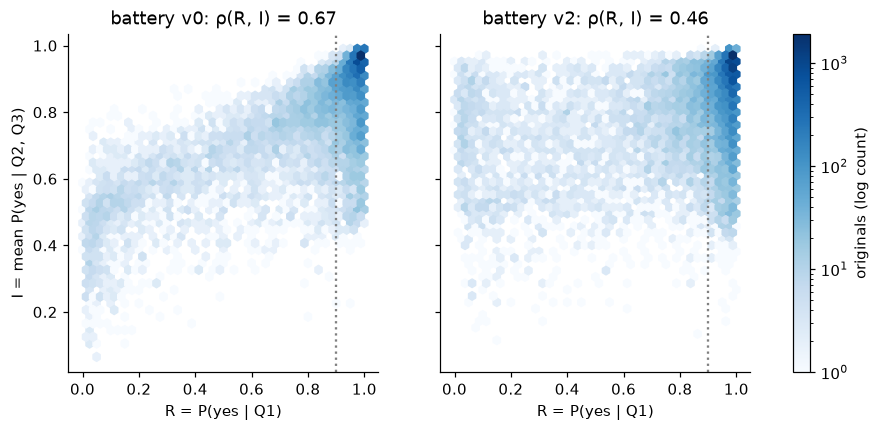

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, v in zip(axes, ("v0", "v2")):
    o = R[f"full {v}"]["orig"]
    hb = ax.hexbin(o["R"], o["I"], gridsize=40, bins="log", cmap="Blues", mincnt=1)
    ax.set_title(f"battery {v}: ρ(R, I) = {stats.spearmanr(o['R'], o['I'])[0]:.2f}")
    ax.set_xlabel("R = P(yes | Q1)")
    ax.axvline(0.9, ls=":", color="grey")
axes[0].set_ylabel("I = mean P(yes | Q2, Q3)")
fig.colorbar(hb, ax=axes, label="originals (log count)")
fig.savefig(FIG_DIR / "battery_full_R_vs_I.pdf", bbox_inches="tight")
plt.show()

### 6.2 Construct separation on the full pool

The question-by-question AUROCs on the negatives show whether a wrong answer moves each question. The thesis wants only Q1 (R) to move. Q3 may move a little, because its check is regenerated from the wrong answer.

In [12]:
sep = []
for v in ("v0", "v2"):
    r = R[f"full {v}"]
    for c in ("q1", "q2", "q3", "q1p", "q2p", "q3p", "R", "I"):
        a, lo, hi = auc_ci(r, c, n=500)
        sep.append({"battery": v, "score": c, "AUROC on negatives": a, "CI low": lo, "CI high": hi})
display(pd.DataFrame(sep).pivot(index="score", columns="battery", values="AUROC on negatives")
        .loc[["q1", "q1p", "q2", "q2p", "q3", "q3p", "R", "I"]])

battery,v0,v2
score,,
q1,0.942,0.942
q1p,0.939,0.942
q2,0.922,0.500
q2p,0.918,0.500
q3,0.746,0.747
q3p,0.768,0.768
R,0.942,0.942
I,0.930,0.713


### 6.3 Consequences for the downstream experiments

The selection conditions depend on how items rank by I:

- **E1-C:** Top-V, Top-I residualised, and the I × S cells within R ≥ 0.9.
- **E2:** the I quintiles.

The tables below show how much those rankings move between v0 and v2. This is the size of the sensitivity analysis the paper will report.

In [13]:
ov = []
for ds, g0 in f0.groupby("dataset"):
    g2 = f2.loc[g0.index]
    for label, mask0, mask2 in (("all originals", slice(None), slice(None)),
                                ("R ≥ 0.9 (both versions)", (g0["R"] >= 0.9) & (g2["R"] >= 0.9), (g0["R"] >= 0.9) & (g2["R"] >= 0.9))):
        a, b = g0.loc[mask0], g2.loc[mask2]
        top_a = set(a["I"].nlargest(int(0.2 * len(a))).index)
        top_b = set(b["I"].nlargest(int(0.2 * len(b))).index)
        hi_a = set(a.index[a["I"] >= a["I"].median()])
        hi_b = set(b.index[b["I"] >= b["I"].median()])
        q0 = pd.qcut(a["I"].rank(method="first"), 5, labels=False)
        q2 = pd.qcut(b["I"].rank(method="first"), 5, labels=False)
        ov.append({"dataset": ds, "set": label, "n": len(a),
                   "ρ(I v0, I v2)": stats.spearmanr(a["I"], b["I"])[0],
                   "top-20% I overlap": len(top_a & top_b) / max(len(top_a), 1),
                   "same side of I median": (len(hi_a & hi_b) + len((set(a.index) - hi_a) & (set(b.index) - hi_b))) / len(a),
                   "same I quintile": float((q0 == q2.reindex(q0.index)).mean())})
display(pd.DataFrame(ov).set_index(["dataset", "set"]))
for v in ("v0", "v2"):
    o = R[f"full {v}"]["orig"]
    print(f"{v}: share of originals with R ≥ 0.9 — FinQA {(o.loc[o['dataset'] == 'finqa', 'R'] >= 0.9).mean():.3f}, "
          f"TAT-QA {(o.loc[o['dataset'] == 'tatqa', 'R'] >= 0.9).mean():.3f}")

n  ρ(I v0, I v2)  top-20% I overlap  \
dataset set                                                                
finqa   all originals             6143          0.804              0.610   
        R ≥ 0.9 (both versions)   3491          0.784              0.562   
tatqa   all originals            13115          0.862              0.684   
        R ≥ 0.9 (both versions)  11116          0.855              0.675   

                                 same side of I median  same I quintile  
dataset set                                                              
finqa   all originals                            0.836            0.504  
        R ≥ 0.9 (both versions)                  0.798            0.483  
tatqa   all originals                            0.850            0.582  
        R ≥ 0.9 (both versions)                  0.844            0.559

v0: share of originals with R ≥ 0.9 — FinQA 0.586, TAT-QA 0.856
v2: share of originals with R ≥ 0.9 — FinQA 0.586, TAT-QA 0.857


**Consequences for E1-C and E2.** The reliability filter is the same under both batteries, but the I-based selections are not:

- Only **56–68%** of the top-20% I items are the same under v0 and v2.
- About **80–85%** of items stay on the same side of the I median, which is what defines the I × S cells.
- Only about **half** stay in the same I quintile (E2).

The battery choice therefore changes *which* items the selection conditions draw. Reporting E1–E3 under both batteries is a real robustness test, not a formality. If H2–H4 hold under v2 but not under v0, that is evidence that the answer-leakage component of v0's I was masking or creating the effect, and the paper must say which.

### 6.4 A third definition: I from Q3 alone

Q2 is the component that changed between versions. A natural question is whether the results depend on including it at all. **I\_Q3 = P(yes | Q3)** (with I\_Q3′ = P(yes | Q3′)) uses only the consequence question. That is the most literal operationalisation of the thesis's "implication strength given the datum is true". Q3's wording is identical in every battery, so I\_Q3 does not depend on the battery choice.

**Status: pre-specified robustness analysis** (owner decision, recorded in the plan, Spec 3 A3b and Spec 5 on 25 October 2026, before any G or C measurement). The primary I remains v2's mean of Q2 and Q3, and gates are decided on it.

In [14]:
defs = {"v0: mean(Q2, Q3)": ("full v0", "I", "I_para"), "v2: mean(Q2, Q3) — primary": ("full v2", "I", "I_para"),
        "Q3 only (v2 run)": ("full v2", "q3", "q3p"), "Q3 only (v0 run)": ("full v0", "q3", "q3p")}
rows = {}
for label, (run, ic, ip) in defs.items():
    r = R[run]; o = r["orig"]
    fq, tq = o[o["dataset"] == "finqa"], o[o["dataset"] == "tatqa"]
    hi = o[o["R"] >= 0.9]
    rows[label] = {
        "D3: ρ(R, I) all": fmt(rho_ci(o["R"], o[ic])),
        "D3: ρ(R, I) FinQA": fmt(rho_ci(fq["R"], fq[ic])),
        "D3: ρ(R, I) TAT-QA": fmt(rho_ci(tq["R"], tq[ic])),
        "AUROC of I on negatives": f"{auc_ci(r, ic, n=200)[0]:.3f}",
        "AUROC of R on negatives": f"{auc_ci(r, 'R', n=200)[0]:.3f}",
        "ρ(I, I′) paraphrase": fmt(rho_ci(o[ic], o[ip])),
        "median I [IQR]": f"{o[ic].median():.2f} [{o[ic].quantile(.25):.2f}, {o[ic].quantile(.75):.2f}]",
        "SD of I": f"{o[ic].std():.3f}",
        "share I ≥ 0.95": f"{(o[ic] >= 0.95).mean():.3f}",
        "share I ≥ 0.99": f"{(o[ic] >= 0.99).mean():.3f}",
        "distinct I values": int(o[ic].round(4).nunique()),
        "within R ≥ 0.9: SD of I": f"{hi[ic].std():.3f}",
        "within R ≥ 0.9: share I ≥ 0.95": f"{(hi[ic] >= 0.95).mean():.3f}",
    }
idefs = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", None):
    display(idefs)

,"v0: mean(Q2, Q3)","v2: mean(Q2, Q3) — primary",Q3 only (v2 run),Q3 only (v0 run)
"D3: ρ(R, I) all","0.674 [0.666, 0.681]","0.458 [0.446, 0.469]","0.180 [0.166, 0.193]","0.179 [0.166, 0.193]"
"D3: ρ(R, I) FinQA","0.804 [0.795, 0.812]","0.516 [0.498, 0.534]","0.336 [0.314, 0.358]","0.335 [0.313, 0.357]"
"D3: ρ(R, I) TAT-QA","0.560 [0.548, 0.572]","0.356 [0.341, 0.371]","0.179 [0.162, 0.195]","0.178 [0.162, 0.195]"
AUROC of I on negatives,0.930,0.713,0.747,0.746
AUROC of R on negatives,0.942,0.942,0.942,0.942
"ρ(I, I′) paraphrase","0.942 [0.941, 0.944]","0.956 [0.955, 0.958]","0.922 [0.920, 0.924]","0.923 [0.921, 0.925]"
median I [IQR],"0.92 [0.79, 0.96]","0.89 [0.78, 0.94]","0.96 [0.88, 0.98]","0.96 [0.88, 0.98]"
SD of I,0.151,0.133,0.176,0.176
share I ≥ 0.95,0.353,0.214,0.613,0.612
share I ≥ 0.99,0.002,0.000,0.121,0.123


In [15]:
# Selection consequences of I_Q3 within R >= 0.9, per dataset: ties at the top-20% cutoff and at the median,
# and agreement with the primary I's selections.
o2 = R["full v2"]["orig"]
tie = []
for ds, g in o2.groupby("dataset"):
    g = g[g["R"] >= 0.9]
    k = int(0.2 * len(g))
    cut = g["q3"].nlargest(k).min()
    top_p = set(g["I"].nlargest(k).index)
    top_q = set(g["q3"].nlargest(k).index)
    tie.append({"dataset": ds, "R ≥ 0.9 items": len(g), "top-20% slots": k, "I_Q3 cutoff value": cut,
                "items at or above cutoff": int((g["q3"] >= cut).sum()),
                "share of slots decided by ties": 1 - int((g["q3"] > cut).sum()) / k,
                "items exactly at I_Q3 median": f"{(g['q3'] == g['q3'].median()).mean():.1%}",
                "top-20% overlap with primary I": len(top_p & top_q) / k,
                "same side of median as primary I": float(((g["I"] >= g["I"].median()) == (g["q3"] >= g["q3"].median())).mean())})
display(pd.DataFrame(tie).set_index("dataset"))
q3c = pd.read_parquet(CODE / "runs" / RUNS["full v2"] / "data" / "q3_checks.parquet").set_index("item_id")["source"]
src = o2.join(q3c)
print("ρ(R, I_Q3) by Q3 check source:",
      {k: round(stats.spearmanr(g["R"], g["q3"])[0], 3) for k, g in src.groupby("source")},
      "| ρ(I_Q3, primary I):", round(stats.spearmanr(o2["q3"], o2["I"])[0], 3))

,R ≥ 0.9 items,top-20% slots,I_Q3 cutoff value,items at or above cutoff,share of slots decided by ties,items exactly at I_Q3 median,top-20% overlap with primary I,same side of median as primary I
dataset,,,,,,,,
finqa,3601,720,0.99,1230,1.000,23.4%,0.335,0.708
tatqa,11238,2247,0.98,3834,0.713,16.4%,0.399,0.739


ρ(R, I_Q3) by Q3 check source: {'llm': np.float64(0.056), 'template': np.float64(0.225)} | ρ(I_Q3, primary I): 0.598


**Findings for I\_Q3.**

- **Gates and validity.** With I\_Q3, R and I become nearly independent: ρ(R, I) = 0.18, FinQA 0.34. D3 would pass by a wide margin. R and its validity (AUROC 0.94) are unchanged. I\_Q3's AUROC on wrong answers is 0.75; it is not 0.5, because each negative's Q3 check is regenerated from its own wrong answer. The results are identical on the v0 and v2 runs, so I\_Q3 is immune to the battery choice and to the disclosed C2 exception.
- **Measurement.** I\_Q3 sits near its ceiling: 61% of originals have I\_Q3 ≥ 0.95, 12% have I\_Q3 ≥ 0.99, and only 98 distinct values occur. Within R ≥ 0.9, two thirds are at 0.95 or above. As a result, within R ≥ 0.9 **every one of FinQA's 720 top-20% slots would be filled by tie-breaking**: no item scores above the 0.99 cutoff, and 1,230 items share it. In TAT-QA, 71% of slots would be. Also, 16–23% of items sit exactly at the median. Selections by I\_Q3 therefore depend heavily on the tie-breaking rule, which is still placeholder P8.
- **Different items.** Selections differ substantially from the primary I: only a third to two fifths of the top-20% items overlap.
- **Construct.** I\_Q3 measures only "the answer entails one generated check", mostly an ordering or direction statement. Its residual link with R comes mainly from template checks. And it depends entirely on the Q3 checks, which are not yet human-validated.

**Why it is a robustness analysis and not the primary I.** It answers the reviewer question "is the effect driven by determinacy or by consequence?" and it does not depend on the battery. But its ceiling and ties make the selection conditions fragile, and adopting it as primary would be another change to the pre-registered definition of I after seeing data.

### 6.5 Notes for the downstream analyses (to do later)

These notes record what must be compared once Specs 2–6 produce results. They are also in the plan and in Specs 3 and 5.

1. **Every result that uses I must be reported under three definitions:**
   - **primary I:** battery v2, mean of Q2 and Q3;
   - **I\_v0:** the pre-registered battery v0, the sensitivity analysis;
   - **I\_Q3:** Q3 only, the robustness analysis.

   This covers Spec 3 (A1's AUROC of I, A2's correlations of I with base-model accuracy, PVI and ICL-reducible loss, A3, A5's cell sizes), Spec 5 (H2–H4 under G and C, with the I-based conditions rebuilt for each definition) and Spec 6 (E3's high-I × high-S cell).
2. **Gates D2–D4 are decided on the primary I only.** For I\_v0 and I\_Q3, report whether any gate *would* have reached a different decision.
3. **One verdict table for the paper:** each hypothesis's verdict under the primary I, I\_v0 and I\_Q3. A hypothesis that holds under all three is robust to how I is measured. One that holds only under some definitions must be reported as such, and is itself evidence about which component of I (determinacy or consequence) carries the effect.
4. **For I\_Q3, also report the share of each top-20%, quintile and median-split selection that was decided by tie-breaking** (§6.4). Use the same tie-breaking rule as the primary conditions once P8 is decided.
5. **The analysis frame must carry `I_v0`, `I_Q3` and `I_Q3_para`** next to the primary `I`. `I_v0` comes from `code/runs/full_v0_2026-10-24/`; `I_Q3` from the primary run's Q3 column.

## 7. What the three versions teach, and what it means for the paper

The interpretation sections below use the full-pool numbers printed above. The pilot numbers are cited only where the full pool has no counterpart (v1).

### 7.1 A measurement finding: where the R–I coupling comes from

The three versions together split the R–I correlation into two parts:

1. **Answer leakage:** a determinacy question that can see the answer partly checks the answer. This part disappears when the answer is removed (v0 → v2) and is not fixed by rewording alone (v1).
2. **Item-level covariance**, which remains: some questions are genuinely under-determined by their context, and their gold answers are also judged less supported.

For a calibrated judge used as a construct-measurement instrument, this is a reportable result. Wording that asks about determinacy is not enough; the judge must be prevented from seeing the answer. It belongs in the E0 construct-validity section, and it is the core of the D5 fallback paper ("does a calibrated judge separate reliability from implication on verifiable financial QA?").

### 7.2 Hypotheses and gates

| Element | What changes with v2 | Status |
|---|---|---|
| **H1** (Jev scores valid and new) | R's validity is unchanged (AUROC on negatives about 0.94). I no longer re-encodes correctness, so H1's "captures something existing scores do not" now rests on a cleaner I. The ρ(I, base-model accuracy), ρ(I, PVI) and ρ(I, ICL-reducible) parts still need Specs 2–3 | pending (Spec 3) |
| **D1** (R on arithmetic items) | R is essentially unchanged between versions | pending formal Spec 3 run |
| **D3** (separability) | v0 passes overall but crosses 0.8 on FinQA; v2 is far below 0.8 overall and per dataset | under v2: would not fire |
| **D4** (cell sizes) | The R ≥ 0.9 filter is nearly the same; I-median splits differ (§6.3) | pending (needs S) |
| **H2–H5** (I-based selection, dose-response, I × S moderation, false high-I items) | They depend on I rankings. Under v2, I is closer to P(consequence \| datum true), so a positive H4 can no longer be explained as "I is partly R". The v0 sensitivity analysis shows whether conclusions survive the change | pending (Specs 4–6) |
| **H6** (proxy agreement) | Unaffected by the battery | pending |

### 7.3 Decisions and how to report them

- **v0** is the pre-registered battery and is reported in full as the sensitivity analysis.
- **v1** was tested against criteria fixed beforehand and rejected; report it as part of the measurement finding (§7.1).
- **v2** is the primary battery. It **missed one pre-set criterion on the pilot** (C2, ρ(Q1, Q2) ≤ 0.50, observed 0.58; 0.48 on the full pool). It was kept because C2 was designed to detect answer leakage, which C1′ shows v2 does not have; the remaining correlation is item-level. The reasoning came after seeing the result, so the paper must state the miss, the reason, and present v0 alongside.
- **The protocol's own remedy:** D3's pre-registered action is "revise Q2 and Q3 before E1". Both revisions happened before any value measurement (G or C).
- **I\_Q3 (Q3 only)** is a pre-specified robustness analysis, recorded on 25 October 2026 before any G or C measurement. Every analysis of I is reported under the primary I, I\_v0 and I\_Q3 (§6.4–6.5).

In [16]:
o0, o2 = R["full v0"]["orig"], R["full v2"]["orig"]
p0, p2 = R["pilot v0"]["orig"], R["pilot v2"]["orig"]
r0 = rho_ci(o0["R"], o0["I"]); r2 = rho_ci(o2["R"], o2["I"])
fq0 = rho_ci(o0.loc[o0["dataset"] == "finqa", "R"], o0.loc[o0["dataset"] == "finqa", "I"])
fq2 = rho_ci(o2.loc[o2["dataset"] == "finqa", "R"], o2.loc[o2["dataset"] == "finqa", "I"])
q12_0 = stats.spearmanr(o0["q1"], o0["q2"])[0]; q12_2 = stats.spearmanr(o2["q1"], o2["q2"])[0]
auc_q2_0 = auc_ci(R["full v0"], "q2", n=200)[0]
auc_r2 = auc_ci(R["full v2"], "R", n=200)[0]; auc_i2 = auc_ci(R["full v2"], "I", n=200)[0]
auc_i0 = auc_ci(R["full v0"], "I", n=200)[0]
v1q12 = stats.spearmanr(R["pilot v1"]["orig"]["q1"], R["pilot v1"]["orig"]["q2"])[0]
p2q12 = stats.spearmanr(p2["q1"], p2["q2"])[0]
v1auc = auc_ci(R["pilot v1"], "q2", n=200)[0]
text = f'''
METHODS — Jev battery. Reliability R is Jev's P(yes) on a support question (Q1). Implication strength I is
the mean of P(yes) on a determinacy question (Q2) and a consequence question (Q3, which assumes the stated
answer is true and asks whether it entails an item-specific check). In the pre-registered battery (v0), Q2
asked whether the context determines the stated answer uniquely. On the full pool, Q2 correlated
{q12_0:.2f} with Q1 and separated deliberately wrong answers from the originals with AUROC {auc_q2_0:.2f},
so it partly re-measured correctness; R and I correlated at ρ = {r0[0]:.2f} overall and {fq0[0]:.2f} on
FinQA, at our separability threshold of 0.8. Following the protocol's remedy for this gate, and before any
value measurement, we tested two revisions on a 200-item pilot against criteria fixed in advance. Asking Q2
under the assumption that the answer is correct (v1) reduced but did not remove the coupling
(ρ(Q1, Q2) = {v1q12:.2f}; AUROC on wrong answers {v1auc:.2f}). Asking Q2 against the context and question
alone, without the stated answer (v2), removes answer leakage by construction. On the pilot a residual ρ(Q1, Q2) of {p2q12:.2f}
remained, above our pre-set 0.50 (on the full pool it is {q12_2:.2f}), which we attribute to item-level covariance rather than
leakage. We
adopt v2 as the primary battery, disclose this exception, and report every analysis of R and I under the
pre-registered v0 battery as well.

RESULTS — battery comparison (full pool, {len(o2):,} originals). Under v2, ρ(R, I) = {r2[0]:.2f}
(95% CI {r2[1]:.2f}–{r2[2]:.2f}; FinQA {fq2[0]:.2f}), against {r0[0]:.2f} under v0 (FinQA {fq0[0]:.2f}).
R's separation of wrong answers is unchanged (AUROC {auc_r2:.2f}), while I responds far less to wrong
answers (AUROC {auc_i2:.2f}, against {auc_i0:.2f} under v0), as the definition of I as implication given
truth requires.
'''
print(text)


METHODS — Jev battery. Reliability R is Jev's P(yes) on a support question (Q1). Implication strength I is
the mean of P(yes) on a determinacy question (Q2) and a consequence question (Q3, which assumes the stated
answer is true and asks whether it entails an item-specific check). In the pre-registered battery (v0), Q2
asked whether the context determines the stated answer uniquely. On the full pool, Q2 correlated
0.82 with Q1 and separated deliberately wrong answers from the originals with AUROC 0.92,
so it partly re-measured correctness; R and I correlated at ρ = 0.67 overall and 0.80 on
FinQA, at our separability threshold of 0.8. Following the protocol's remedy for this gate, and before any
value measurement, we tested two revisions on a 200-item pilot against criteria fixed in advance. Asking Q2
under the assumption that the answer is correct (v1) reduced but did not remove the coupling
(ρ(Q1, Q2) = 0.75; AUROC on wrong answers 0.85). Asking Q2 against the context and question
al

## 8. Limitations and open points

1. **A post-hoc exception.** v2 missed a pre-set criterion (C2) and was kept. This is disclosed, and v0 is reported alongside, but reviewers may still read it as flexibility. The defence is that the criteria were fixed in advance, the miss is reported, and the pre-registered battery is analysed in full.
2. **Q2 under v2 is item-level.** An original and its negative share it by construction. This is the intended property ("given the datum is true"), but it means Q2 cannot contribute to separating wrong answers at all, so any such separation in I comes from Q3.
3. **The residual ρ(Q1, Q2) is interpreted, not proven.** The item-level covariance reading is the natural one, but alternative explanations, such as Jev's general sensitivity to context quality, are not excluded.
4. **The Q3 checks are not yet human-validated.** This applies to all versions equally. I depends on Q3 in every version.
5. **One Jev version (`jev-1.14.0`), probabilities rounded to 0.01.** Small differences in R between v0 and v2 reflect batching composition and call-to-call noise, not wording.
6. **The pilot criteria were evaluated on 200 originals and 99 pairs**, balanced 50/50 across datasets. The full-pool numbers confirm the direction of every pilot finding (§6). The one criterion v2 missed on the pilot (C2) is met on the full pool, which shows how close to the threshold that decision was.
7. **Downstream selections depend on how I is defined** (§6.3, §6.4), so E1–E3 must be reported under the primary I, I\_v0 and I\_Q3. I\_Q3's selections additionally depend on the tie-breaking rule (P8).